In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import emcee
import corner
from IPython.display import display, Math
from numba import njit
from dynesty import NestedSampler

In [2]:
from values.metrics import metrics
from values.binary_data import name_binary
from analysis.qpo_analysis import calc_freq
from analysis.qpo_analysis import f_U_err_direct
from analysis.qpo_analysis import f_L_err_direct
from models.Schwarzschild import get_radii
from models.Schwarzschild import log_posterior_probability
from models.Schwarzschild import prepare_mcmc_samples
from models.Schwarzschild import ptform
from models.Schwarzschild import log_likelihood_dynesty
from models.Schwarzschild import ISCOs_dynesty

In [3]:
f_U_func,f_U_err_func,f_L_func,f_L_err_func,V_2diff,f,f_diff = calc_freq(metrics["s"])

In [4]:
r_best,ISCOs = get_radii(f_U_func,f_L_func,V_2diff,f,f_diff)

for i in range(len(r_best)):
    display(Math(rf"r_{{best,{i}}} = {r_best[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [5]:
chi_summary=np.round(np.array(r_best)/1000,2)

In [6]:
labels = ["r_0", "r_1", "r_2", "r_3", "r_4"]

In [7]:
n_walkers = 32
n_dim = len(r_best)
n_steps = 10000
pos = r_best - (np.random.randn(n_walkers, n_dim))

f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)

#nwalkers, ndim = pos.shape
sampler = emcee.EnsembleSampler(
    n_walkers, n_dim, log_posterior_probability, args=(f_U_func, f_U_err_direct_numba, f_L_func, f_L_err_direct_numba, ISCOs) 
)
sampler.run_mcmc(pos, n_steps, progress=True)

100%|██████████| 10000/10000 [00:08<00:00, 1127.37it/s]


State([[ 47935.45810381  79340.6779558  100822.54286231  81254.13050514
  113317.19597247]
 [ 48093.04299204  79450.1626339  100890.66759533  81276.58446158
  115969.79048941]
 [ 48668.07243278  75382.17279274 103213.4020251   81295.10551708
  114353.42051067]
 [ 48353.80401053  80693.36060431 100183.97638143  80941.04230169
  110104.16042576]
 [ 48375.18859459  77877.04577335  98378.41127628  81019.14476336
  115480.68451475]
 [ 48223.54832066  79785.30022529  97917.01021856  81892.70197887
  122908.24337244]
 [ 48019.4635591   80846.62199116 103311.88428522  81908.93050588
  111980.05970288]
 [ 48130.33336752  77521.01287961 102037.28477783  81960.24034347
  115659.38979309]
 [ 47971.27535301  79969.42419421 109039.67167676  80809.948971
  116597.50544307]
 [ 47965.37897593  78008.03329059 102974.84806086  81934.04141648
  124913.02023451]
 [ 48228.19404189  80805.57734113  99350.09197337  80940.0318221
  115042.77091593]
 [ 47864.13259594  78047.37195934 101549.84973543  80894.47847

(10000, 32, 5)


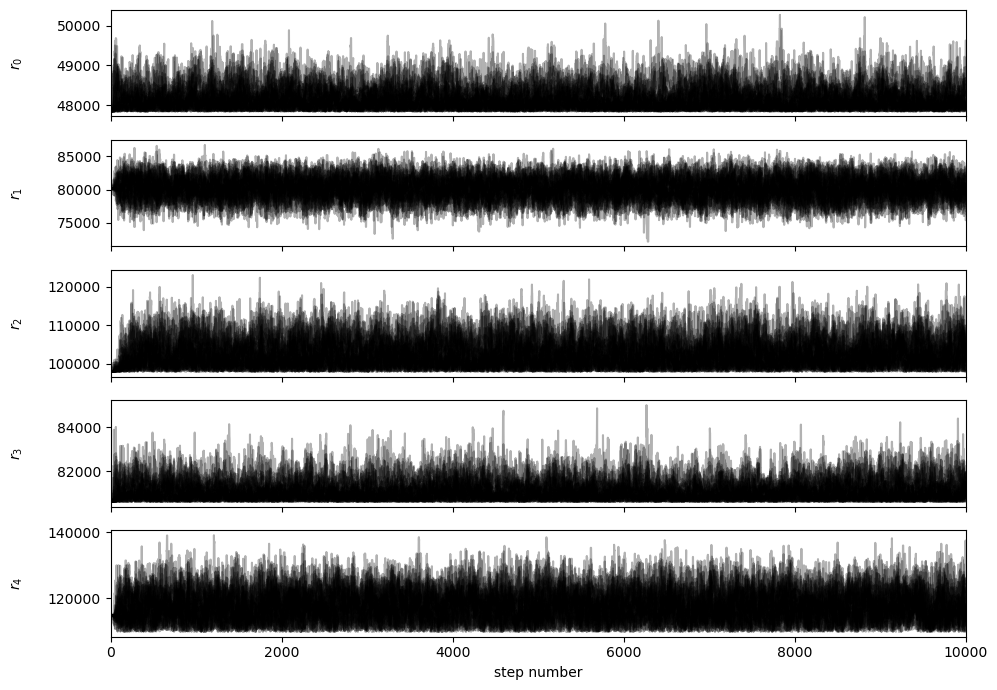

In [8]:
fig, axes = plt.subplots(n_dim, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
print(samples.shape)
for i in range(n_dim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))

    ax.set_ylabel(fr"${labels[i]}$")
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.tight_layout()

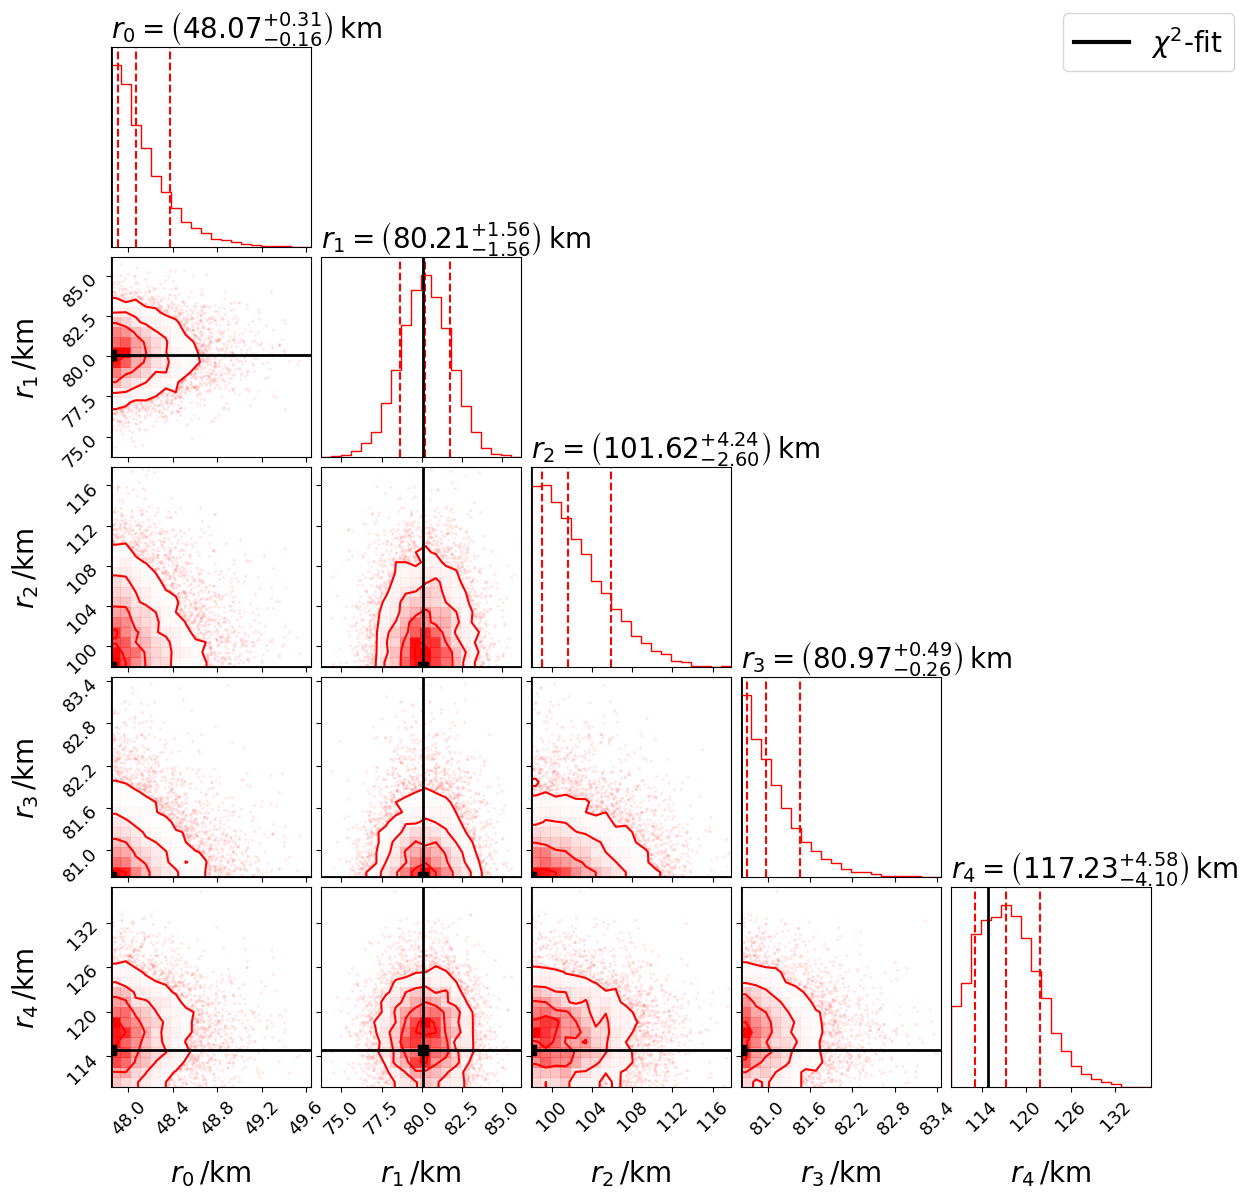

In [9]:
plt.rcParams.update({'font.size': 20,'xtick.labelsize': 13,'ytick.labelsize': 13})
flat_samples = prepare_mcmc_samples(sampler)
fig = corner.corner(
    flat_samples/1000, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 20},color="red",labelpad=0.05
)

mcmc_quantiles = np.array([corner.quantile(flat_samples[:, i],(0.16, 0.5, 0.84))for i in range(flat_samples.shape[1])])
mcmc_summary = np.column_stack((np.round(mcmc_quantiles[:, 1]/1000,2),np.round((mcmc_quantiles[:, 0] - mcmc_quantiles[:, 1])/1000,2),np.round((mcmc_quantiles[:, 2] - mcmc_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(n_dim, n_dim)

for i, label in enumerate(labels):
    mcmc_title = (
        rf"${label} = "
        rf"\left({mcmc_summary[:,0][i]:.2f}"
        rf"^{{+{mcmc_summary[:,2][i]:.2f}}}_{{{mcmc_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(mcmc_title,fontsize=20,loc="left",)
truths=np.array(r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
fig.legend(handles=[legend_line])
plt.savefig("../results/s_mcmc.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

In [10]:
values = []
for i in range(n_dim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)
    txt = "{3} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], labels[i])
    display(Math(txt))
    values.append(mcmc[1])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
ndim = len(r_best)
f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)
ISCOs_dyn = ISCOs_dynesty(V_2diff,f,f_diff)

dyn_sampler = NestedSampler(log_likelihood_dynesty, ptform, ndim, logl_args=(f_U_func, f_U_err_direct_numba, f_L_func, f_L_err_direct_numba), ptform_args=(ISCOs_dyn,),nlive = 1000)

dyn_sampler.run_nested()

100%|█████████▉| 20930/20931 [00:19<00:00, 1070.27it/s, +1000 | bound: 69 | nc: 1 | ncall: 105956 | eff(%): 20.894 | loglstar: -57.604 | logz: -78.651 +/-  0.159 | dlogz:  0.001 >  1.009]


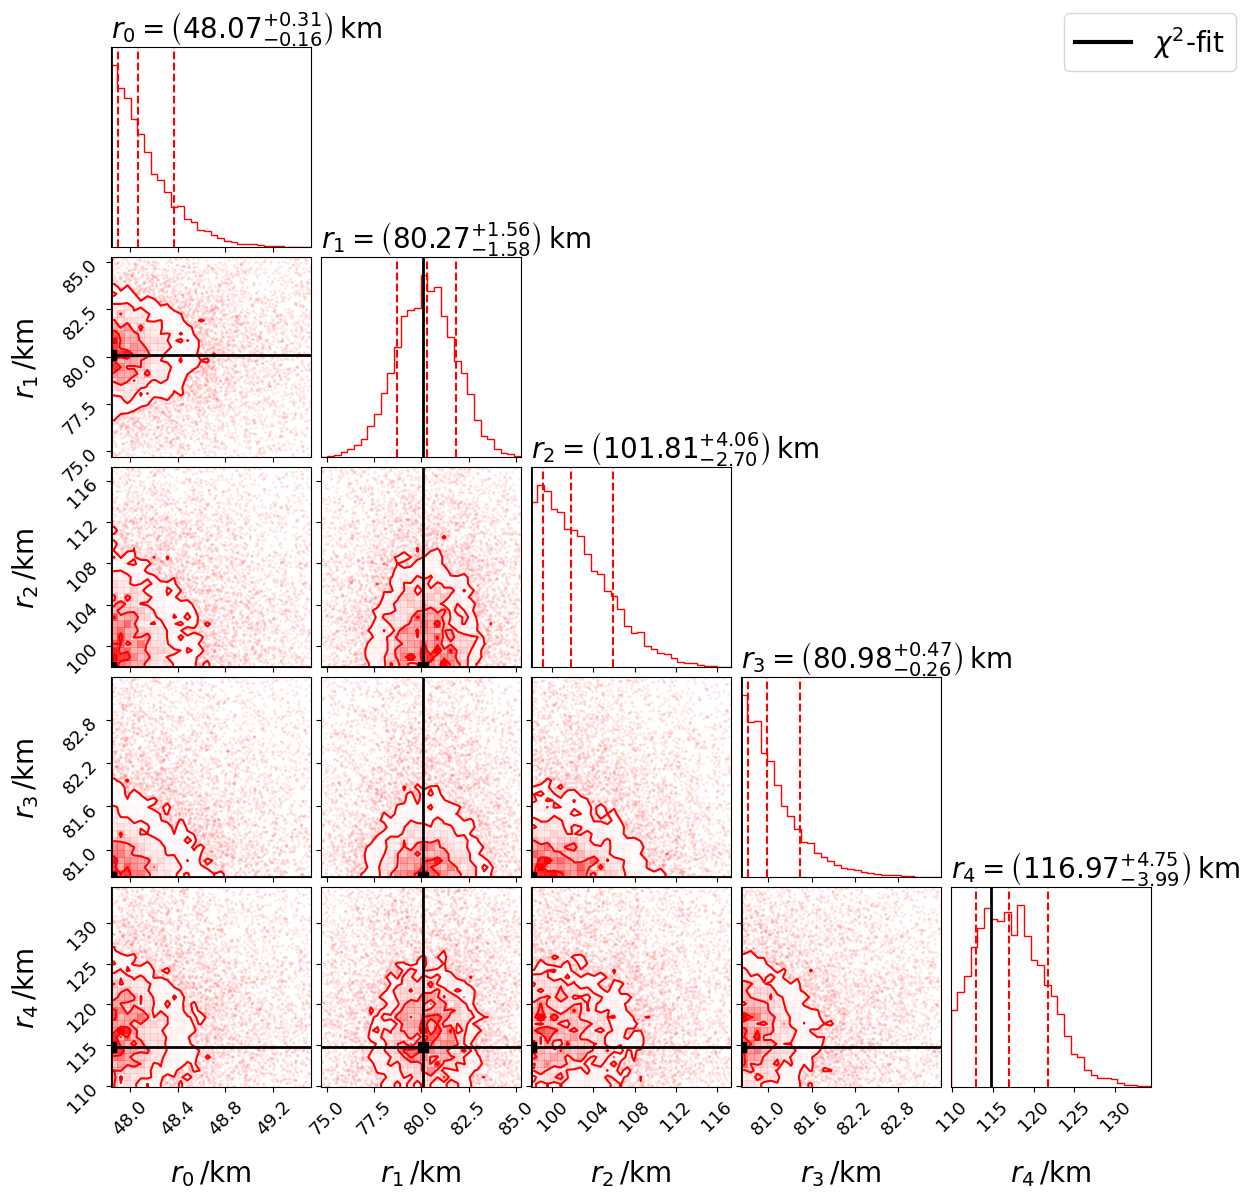

In [12]:
plt.rcParams.update({'font.size': 20,'xtick.labelsize': 13,'ytick.labelsize': 13})
dyn_results = dyn_sampler.results
dyn_samples = dyn_results.samples.copy()
dyn_weights = dyn_results.importance_weights()

fig = corner.corner(
    dyn_samples/1000, weights=dyn_weights, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], bins=30, quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 20},color="red",range=[0.999] * dyn_samples.shape[1],labelpad=0.05
)

dyn_quantiles = np.array([corner.quantile(dyn_samples[:, i],(0.16, 0.5, 0.84), weights=dyn_weights)for i in range(dyn_samples.shape[1])])
dyn_summary = np.column_stack((np.round(dyn_quantiles[:, 1]/1000,2),np.round((dyn_quantiles[:, 0] - dyn_quantiles[:, 1])/1000,2),np.round((dyn_quantiles[:, 2] - dyn_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(ndim, ndim)

for i, label in enumerate(labels):
    dyn_title = (
        rf"${label} = "
        rf"\left({dyn_summary[:,0][i]:.2f}"
        rf"^{{+{dyn_summary[:,2][i]:.2f}}}_{{{dyn_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(dyn_title,fontsize=20,loc="left",)
truths=np.array(r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
fig.legend(handles=[legend_line])
plt.savefig("../results/s_dynesty.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

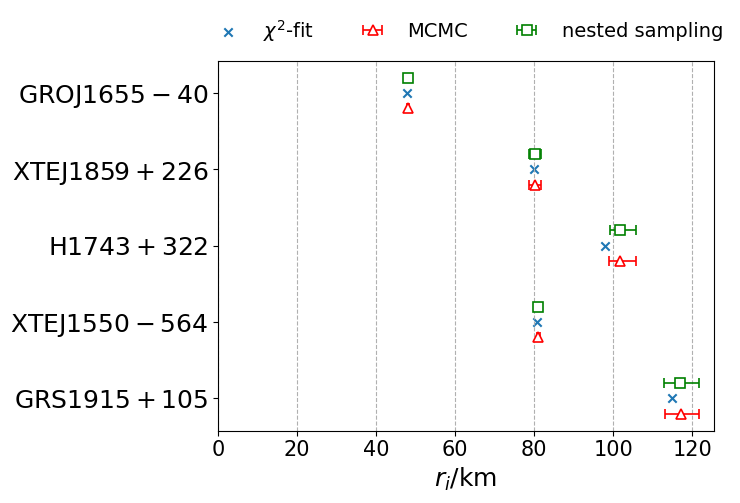

In [13]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(chi_summary)))
plt.scatter(chi_summary, y,marker="x", label="$\chi^2$-fit")
plt.errorbar(mcmc_summary[:, 0], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
plt.errorbar(dyn_summary[:, 0], y-0.2,xerr=np.abs(dyn_summary[:, 1:3]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)

new_labels = [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
plt.xlabel("$r_i$/km")
plt.legend(loc="lower center",bbox_to_anchor=(0.5, 1),ncol=3,fontsize=14,frameon=False)
plt.grid(axis="x",linestyle="dashed")
plt.gca().invert_yaxis()
plt.xlim(left=0)

plt.savefig("../results/s_values.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

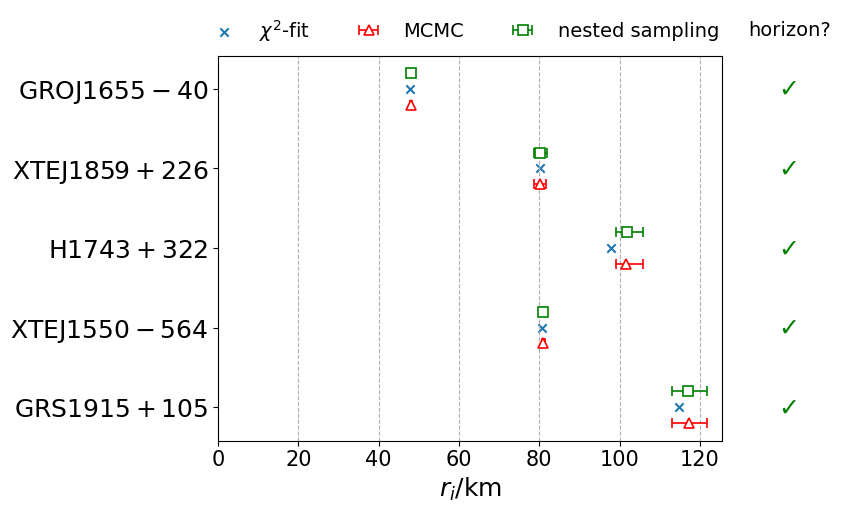

In [14]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(chi_summary)))
fig = plt.figure(figsize=(8, 5))
gs = fig.add_gridspec(1, 2,width_ratios=[5, 1],wspace=0.05)

ax = fig.add_subplot(gs[0, 0])
ax_table = fig.add_subplot(gs[0, 1], sharey=ax)
ax.scatter(chi_summary, y,marker="x", label="$\chi^2$-fit")
ax.errorbar(mcmc_summary[:, 0], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
ax.errorbar(dyn_summary[:, 0], y-0.2,xerr=np.abs(dyn_summary[:, 1:3]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)

new_labels = [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
ax.set_xlabel("$r_i$/km")

ax.grid(axis="x",linestyle="dashed")
ax.set_xlim(left=0)
ax.invert_yaxis()

ax_table.set_xticks([])

# shared y axis with main plot
ax_table.set_yticks(y)
ax_table.tick_params(axis="y", left=False, labelleft=False)

for i in y:
    symbol = r"$\checkmark$"
    color = "green"

    ax_table.text(0.5, i,symbol,ha="center",va="center",fontsize=18,color=color)

for spine in ax_table.spines.values():
    spine.set_visible(False)
    
ax_table.tick_params(axis="x",length=0,labelsize=14,pad=10)

fig.legend(loc="center",bbox_to_anchor=(0.43, 0.93),bbox_transform=fig.transFigure,ncol=3,fontsize=14,frameon=False)

fig.text(0.84, 0.93,"horizon?",transform=fig.transFigure,ha="center",va="center",fontsize=14)

plt.savefig("../results/s_values_checklist.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

In [15]:
dyn_values = np.sum(dyn_samples * dyn_weights[:, None],axis=0)
for i in range(len(dyn_values)):
    display(Math(f"{labels[i]} = {dyn_values[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [16]:
logZ = dyn_results.logz[-1]
logZ_err = dyn_results.logzerr[-1]

print("log(Z) =", logZ)
print("error of log(Z) =", logZ_err)

log(Z) = -78.65092760953635
error of log(Z) = 0.33906533717928694
